# Fig. 7 — Axion-active phonons of MnBi₂Te₄ (paper `main2.tex`, `fig:mbt`)

Draft, 2026-10-31. Run all; the last cell writes `paper/figures/fig7.pdf` (and `.png`). Everything is at the production
window `f10.962_w12.810_k8`, base end (`END = 0`), Q = 0.01 Å.

| panel | content | data |
|---|---|---|
| (a) | side view of two septuple layers (SL) with MnTe₆ / BiTe₆ octahedra; arrows: each T₂⁻ normal mode's displacement along c (largest = `ARROW` Å on the plot). Title: frequency, and dθ per Å of total displacement \|Δr\| (sign of the eigenvector). The 17.8 cm⁻¹ rigid-layer mode is framed | Φ from the forces of the four basis runs at Q = 0.03 Å (method 1 of `analysis/phonon_frequencies.ipynb`); dθ/dQ of each pattern from `windows/f10.962_w12.810_k8/dtheta_<structure>/dtheta.npz` (production tube list 16, 4, 3, 8) |
| (b) | ∂θ/∂Q of the four basis patterns vs the in-plane subdivision m, the number of k_z planes, and the half-width of the subdivided region; in each, the other two settings at their densest values (m 16, 32 planes, half-width 5). Dotted: the production list | `dtheta_dense_<structure>/` (tube list 16, 16, 5, 32, 995,552 k; `analysis/studies/2026-10-30_k_density/c2_dense.sh`). The cell checks that it reproduces the production value at (m 4, 8 planes, half-width 3) |
| (c) | integrand of ∂θ/∂u (rad Å, per Å of \|Δr\|) for the 128.7 and 17.8 cm⁻¹ modes on the k_z = 0 and Z planes, with direct-gap contours. c2 is linear in the displacement, so a mode's integrand is Σᵢ Cᵢₙ c2ᵢ / \|Δr\| / V_BZ | `c2_maps_<structure>/` (121² points per plane, step 0.005 Å⁻¹; `analysis/studies/2026-10-30_c2_maps/c2_maps.sh`) |


In [1]:
# ---- settings
import re
from pathlib import Path
ROOT = Path("/Users/treycole/Repos/axion-phonon")
MBT = ROOT / "data/MnBi2Te4"
PREFIX = "MnBi2Te4"
# (a) phonons: base SCF and the four T2- basis runs at Q = 0.03 Å (force constants, method 1 of phonon_frequencies.ipynb)
BASE_SCF = MBT / "phonons/base_forces/out"
BASIS_RUNS = [MBT / f"phonons/force_constants/T2-_p{i}_Q0.03/out" for i in (1, 2, 3, 4)]
BASIS_NAMES = ["Mn", "Bi", "Te1", "Te2"]
Q_BASIS = 0.03                       # Å
MASS = {"Mn": 54.9380, "Bi": 208.9800, "Te": 127.6030}   # amu
# dθ/dQ of each basis pattern, production window f10.962_w12.810, Q = 0.01 Å, production tube list (16, 4, 3, 8)
PRODUCTION = MBT / "windows/f10.962_w12.810_k8"
DTHETA = [PRODUCTION / f"dtheta_T2-_p{i}_Q0.01/dtheta.npz" for i in (1, 2, 3, 4)]
END = 0                              # 0: base end (the paper's estimate), 1: structure end
# (b) the dense tube list (16, 16, 5, 32), which contains the production list (analysis/studies/2026-10-30_k_density/)
DENSE = [PRODUCTION / f"dtheta_dense_T2-_p{i}_Q0.01" for i in (1, 2, 3, 4)]
PROD_POINT = dict(m=4, n3=8, half=3)
# (c) c2 on the k_z = 0 and Z planes, production window (analysis/studies/2026-10-30_c2_maps/)
MAPS = [PRODUCTION / f"c2_maps_T2-_p{i}_Q0.01" for i in (1, 2, 3, 4)]
MAP_WIN = PRODUCTION / "base/out/MnBi2Te4.win"           # cell (Å) for the BZ volume
MAP_MODES = [128.7, 17.8]            # cm^-1, nearest mode is used
MAP_HALF = 0.25                      # 1/Å, half-width shown
RHO_MAX = 3000                       # rad Å, colour range of the mode maps
GAP_LEVELS = [0.25, 0.3, 0.4]        # eV, direct-gap contours
FIGSIZE = (7.0, 5.6)
FONT_SIZE = 8
SAVE_FIG = ROOT / "paper/figures/fig7.pdf"   # or None
# ---------------
import sys
import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm, to_rgb
from matplotlib.patches import Polygon, FancyArrowPatch, FancyBboxPatch
from matplotlib.lines import Line2D
from scipy.spatial import ConvexHull
sys.path.insert(0, str(ROOT))
from axion_phonon import tube

RY_EV, BOHR_A = 13.605693, 0.529177
CM = np.sqrt(1.602176634e-19 / 1e-20 / 1.66053907e-27) / (2 * np.pi * 2.99792458e10)   # sqrt(eV/Å²/amu) -> cm^-1

def read_scf(run):
    txt_in = (run / f"{PREFIX}.scf.in").read_text()
    blk = txt_in.split("ATOMIC_POSITIONS angstrom")[1].split("K_POINTS")[0]
    rows = [l.split() for l in blk.strip().splitlines() if l.strip()]
    cell = np.array([l.split() for l in txt_in.split("CELL_PARAMETERS angstrom")[1].strip().splitlines()[:3]], float)
    pos = np.array([r[1:4] for r in rows], float)
    txt = (run / f"{PREFIX}.scf.out").read_text()
    f = txt.split("Forces acting on atoms")[-1]
    force = np.array(re.findall(r"atom\s+\d+ type\s+\d+\s+force =\s+(\S+)\s+(\S+)\s+(\S+)", f)[:len(pos)], float) * RY_EV / BOHR_A
    return [re.sub(r"\d", "", r[0]) for r in rows], pos, force, cell

In [2]:
# ---- (a) normal modes: Φ C = ω² M C, Φ from the forces of the basis runs (production method 1)
species, R0, F0, A = read_scf(BASE_SCF)
runs = [read_scf(r) for r in BASIS_RUNS]
V = np.array([(r[1] - R0) / Q_BASIS for r in runs])              # (4, nat, 3) basis vectors
mass = np.array([MASS[s] for s in species])
M = np.einsum("a,iax,jax->ij", mass, V, V)
Phi_raw = -np.einsum("iax,jax->ij", V, np.array([r[2] for r in runs]) - F0) / Q_BASIS
w2, C = scipy.linalg.eigh((Phi_raw + Phi_raw.T) / 2, M)          # C[:, n]: mode n, C^T M C = 1 amu
freq = np.sign(w2) * np.sqrt(np.abs(w2)) * CM
U = np.einsum("in,iax->nax", C, V)                               # (4, nat, 3) displacement of each mode
L = np.linalg.norm(U.reshape(4, -1), axis=1)
assert np.abs(V[..., :2]).max() < 1e-6, "T2- displacements are along c only"
dth = np.array([np.load(f)["dtheta"][2, 0, END] for f in DTHETA])   # rad/Å per basis pattern (m 4, 8 planes)
coupling = (dth @ C) / L                                         # rad per Å of |Δr|, sign of the eigenvector
print("dθ/dQ per pattern, production (rad/Å):", dth.round(5))
for n in range(4):
    print(f"  mode {freq[n]:6.1f} cm-1: {coupling[n]:+.3f} rad/Å")

dθ/dQ per pattern, production (rad/Å): [-1.9589   3.81959  6.38695 -4.54479]
  mode   17.8 cm-1: -1.446 rad/Å
  mode   82.7 cm-1: +0.103 rad/Å
  mode  128.7 cm-1: +3.633 rad/Å
  mode  143.3 cm-1: -0.616 rad/Å


In [3]:
# ---- (b) dθ/dQ vs k density, from the dense list: vary one setting, the other two at their densest values
MS, N3S, HALVES = [1, 2, 4, 8, 16], [4, 8, 16, 32], [0, 1, 2, 3, 4, 5]
conv = np.zeros((4, 3), dtype=object)
dense = np.zeros(4)
for p, D in enumerate(DENSE):
    kl = dict(np.load(D / "klist.npz"))
    c2 = np.full(len(kl["k"]), np.nan, complex)
    for f in sorted((D / "c2").glob("out_*/chunks/chunk_*.npz")):
        z = np.load(f)
        c2[z["idx"]] = z["c2"][:, END]
    assert not np.isnan(c2.real).any(), f"{D}: missing chunks"
    top = dict(m=MS[-1], n3=N3S[-1], half=HALVES[-1])
    conv[p] = [[tube.integrate_at(c2, kl, **{**top, key: v}) for v in vals] for key, vals in (("m", MS), ("n3", N3S), ("half", HALVES))]
    dense[p] = tube.integrate_at(c2, kl, **top)
    prod = tube.integrate_at(c2, kl, **PROD_POINT)
    assert abs(prod - dth[p]) < 1e-5 * abs(dth[p]), (prod, dth[p])
    print(f"{BASIS_NAMES[p]:4s} production {dth[p]:+.5f}  dense {dense[p]:+.5f}  ({100 * (dth[p] / dense[p] - 1):+.3f}%)")
print("mode couplings with the dense values:", ((dense @ C) / L).round(3))

Mn   production -1.95890  dense -1.95884  (+0.003%)


Bi   production +3.81959  dense +3.81468  (+0.129%)


Te1  production +6.38695  dense +6.38429  (+0.042%)


Te2  production -4.54479  dense -4.53723  (+0.167%)
mode couplings with the dense values: [-1.444  0.106  3.631 -0.615]


In [4]:
# ---- (c) normal-mode integrand on the k_z = 0 and Z planes: c2 is linear in the displacement, so mode = Σ C_in pattern
kl_map = np.load(MAPS[0] / "klist.npz")
c2m = np.full((4, len(kl_map["k"])), np.nan); gap = np.full(len(kl_map["k"]), np.nan)
for p, D in enumerate(MAPS):
    assert np.array_equal(np.load(D / "klist.npz")["k"], kl_map["k"])
    for f in sorted((D / "c2").glob("out_*/chunks/chunk_*.npz")):
        z = np.load(f)
        c2m[p, z["idx"]] = z["c2"][:, END].real; gap[z["idx"]] = z["gap"][:, END]
assert not np.isnan(c2m).any(), "missing map chunks"
lines = MAP_WIN.read_text().splitlines()
i = next(j for j, l in enumerate(lines) if l.strip().lower() == "begin unit_cell_cart")
Aw = np.array([l.split() for l in lines[i + 1:i + 5] if l.split() and l.split()[0].lower() not in ("ang", "bohr")][:3], float)
V_BZ = abs(np.linalg.det(2 * np.pi * np.linalg.inv(Aw).T))
map_modes = [int(np.argmin(np.abs(freq - f))) for f in MAP_MODES]
rho = {n: (C[:, n] @ c2m) / L[n] / V_BZ for n in map_modes}    # rad Å per Å of |Δr|: ∂θ/∂u = ∫ rho d³k
n_side = int(round(np.sqrt((kl_map["plane"] == 0).sum())))
print(f"maps: V_BZ {V_BZ:.4f} 1/Å³, min gap {gap.min():.3f} eV, max |rho|", {round(freq[n], 1): np.abs(rho[n]).max().round(0) for n in map_modes})

maps: V_BZ 0.5590 1/Å³, min gap 0.196 eV, max |rho| {np.float64(128.7): np.float64(2045.0), np.float64(17.8): np.float64(550.0)}


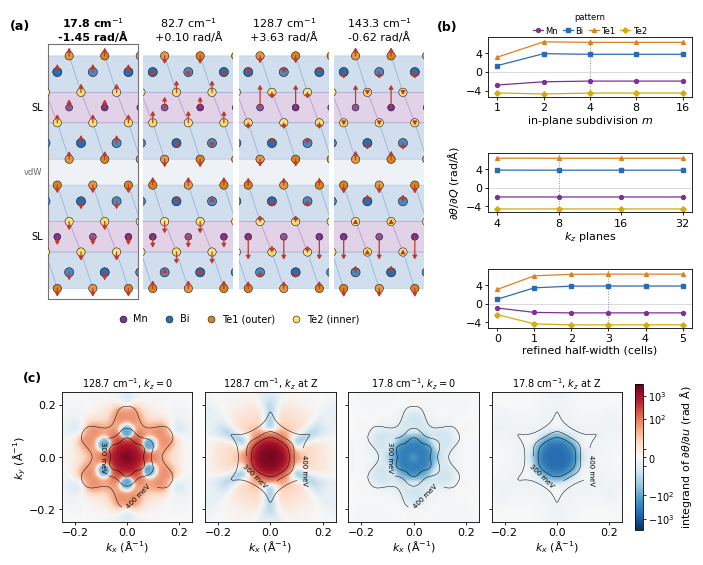

In [5]:
# ---- draw
plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "xtick.major.size": 2.5, "ytick.major.size": 2.5, "mathtext.fontset": "dejavusans"})
fig = plt.figure(figsize=FIGSIZE)
g_top = fig.add_gridspec(1, 2, width_ratios=[4.25, 2.3], wspace=0.22, left=0.065, right=0.985, top=0.95, bottom=0.43)
g_a = g_top[0].subgridspec(2, 4, height_ratios=[1, 0.07], wspace=0.06, hspace=0.02)
g_b = g_top[1].subgridspec(3, 1, hspace=0.95)
g_c = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 0.06], wspace=0.12, left=0.085, right=0.915, top=0.33, bottom=0.07)

# (a) side view of two septuple layers (periodic images, x along the viewing direction), MnTe6 / BiTe6 octahedra,
#     arrows = displacement along c of each normal mode (largest = ARROW Å on the plot)
COL = {"Mn": "#7b3294", "Bi": "#2b6cb0", "Te1": "#d9821e", "Te2": "#f7dc6f"}
RAD = {"Mn": 0.36, "Bi": 0.48, "Te1": 0.44, "Te2": 0.44}
ARROW = 2.4
ZLO, ZHI = -6.6, 20.3
a_in = np.linalg.norm(A[0] - A[2])                              # in-plane lattice constant
YLO, YHI = -1.0, 2 * a_in * np.sqrt(3) / 2 + 1.0
n = np.array(np.meshgrid(*[range(-4, 5)] * 3, indexing="ij")).reshape(3, -1).T
img = (R0[None] + (n @ A)[:, None]).reshape(-1, 3)
atom = np.tile(np.arange(len(R0)), len(n))
mn_z = R0[np.array(species) == "Mn", 2]
period = A[0, 2]                                                 # every lattice vector rises c/3 = 27.284 Å
lab = [s if s != "Te" else ("Te2" if min(abs(((R0[i, 2] - mz + period / 2) % period) - period / 2) for mz in mn_z) < 2.5 else "Te1")
       for i, s in enumerate(species)]

def slab(ylo, yhi, xlo, xhi):
    s = (img[:, 2] > ZLO - 3) & (img[:, 2] < ZHI + 3) & (img[:, 1] > ylo) & (img[:, 1] < yhi) & (img[:, 0] > xlo) & (img[:, 0] < xhi)
    return img[s], atom[s]

P, idx = slab(YLO - 0.6, YHI + 0.6, -0.01, a_in - 0.01)          # one period in depth
P_oct, idx_oct = slab(YLO - 3, YHI + 3, -0.01, a_in - 0.01)      # octahedron centres past the edges (clipped by the axes)
Pall, iall = slab(YLO - 7, YHI + 7, -4, 2 * a_in)
is_te = np.array([lab[i].startswith("Te") for i in iall])
U_c = U[..., 2] / np.abs(U[..., 2]).max()
order = np.argsort(freq)
rigid = int(np.argmin(freq))
for j, nm in enumerate(order):
    ax = fig.add_subplot(g_a[0, j])
    ax.axhspan(5.46, 8.18, color="#eef2f6", zorder=0, lw=0)
    for k in np.argsort(-P_oct[:, 0]):                           # octahedra, back to front (viewer at -x)
        l = lab[idx_oct[k]]
        if l in ("Mn", "Bi"):
            d = np.linalg.norm(Pall - P_oct[k], axis=1)
            nb = Pall[(d > 0.1) & (d < 3.5) & is_te][:, 1:]
            poly = nb[ConvexHull(nb).vertices]
            ax.add_patch(Polygon(poly, closed=True, fc=COL[l], alpha=0.22, ec=COL[l], lw=0.5, zorder=2))
    for k in np.argsort(-P[:, 0]):
        l = lab[idx[k]]
        f = 0.35 * P[k, 0] / a_in                                # fade toward the back
        c = np.array(to_rgb(COL[l])) * (1 - f) + f
        ax.add_patch(plt.Circle((P[k, 1], P[k, 2]), RAD[l], fc=c, ec="k", lw=0.35, zorder=10 + a_in - P[k, 0]))
    for k in range(len(P)):
        d = U_c[nm, idx[k]] * ARROW
        if abs(d) > 0.25:
            ax.add_patch(FancyArrowPatch((P[k, 1], P[k, 2]), (P[k, 1], P[k, 2] + d), arrowstyle="-|>,head_length=2.2,head_width=1.3",
                                         lw=0.9, color="#c0392b", zorder=40, shrinkA=0, shrinkB=0))
    ax.set(xlim=(YLO, YHI), ylim=(ZLO, ZHI), aspect="equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(nm == rigid); s.set_color("0.45"); s.set_linewidth(0.8)
    ax.set_title(f"{freq[nm]:.1f} cm$^{{-1}}$\n{coupling[nm]:+.2f} rad/Å", fontsize=FONT_SIZE, pad=3,
                 fontweight="bold" if nm == rigid else "normal")
    if j == 0:
        ax.text(-0.06, 0.0 / (ZHI - ZLO) + (0 - ZLO) / (ZHI - ZLO), "SL", transform=ax.transAxes, ha="right", va="center", fontsize=FONT_SIZE - 1)
        ax.text(-0.06, (13.64 - ZLO) / (ZHI - ZLO), "SL", transform=ax.transAxes, ha="right", va="center", fontsize=FONT_SIZE - 1)
        ax.text(-0.06, (6.82 - ZLO) / (ZHI - ZLO), "vdW", transform=ax.transAxes, ha="right", va="center", fontsize=FONT_SIZE - 2, color="0.4")
        ax.text(-0.42, 1.06, "(a)", transform=ax.transAxes, fontweight="bold", fontsize=FONT_SIZE + 1)
ax_leg = fig.add_subplot(g_a[1, :]); ax_leg.axis("off")
handles = [Line2D([], [], marker="o", ls="", ms=5, mfc=COL[l], mec="k", mew=0.35, label=t)
           for l, t in (("Mn", "Mn"), ("Bi", "Bi"), ("Te1", "Te1 (outer)"), ("Te2", "Te2 (inner)"))]
ax_leg.legend(handles=handles, loc="center", ncol=4, frameon=False, fontsize=FONT_SIZE - 1, handletextpad=0.1, columnspacing=1.2)

# (b) dθ/dQ vs each tube setting, the other two at their densest values; dotted: the production list
pc = ["#7b3294", "#2b6cb0", "#d9821e", "#d4ac0d"]   # as in (a); Te2 a shade darker for a line
mk = ["o", "s", "^", "D"]
labels = [("in-plane subdivision $m$", MS, "m"), ("$k_z$ planes", N3S, "n3"), ("refined half-width (cells)", HALVES, "half")]
for r, (xl, vals, key) in enumerate(labels):
    ax = fig.add_subplot(g_b[r])
    ax.axhline(0, color="0.8", lw=0.5, zorder=0)
    ax.axvline(PROD_POINT[key], color="0.55", lw=0.7, ls=":", zorder=0)
    for p in range(4):
        ax.plot(vals, conv[p, r], marker=mk[p], ms=2.8, lw=0.9, color=pc[p], mec=pc[p], label=BASIS_NAMES[p])
    if key != "half":
        ax.set_xscale("log", base=2); ax.minorticks_off()
    ax.set_xticks(vals, [str(v) for v in vals])
    ax.set_xlabel(xl, labelpad=1)
    ax.set_ylim(-5.3, 7.5); ax.set_yticks([-4, 0, 4])
    ax.tick_params(pad=1.5)
    if r == 0:
        ax.text(-0.25, 1.12, "(b)", transform=ax.transAxes, fontweight="bold", fontsize=FONT_SIZE + 1)
        ax.legend(title="pattern", title_fontsize=FONT_SIZE - 2, fontsize=FONT_SIZE - 2, ncol=4, frameon=False,
                  loc="lower center", bbox_to_anchor=(0.5, 0.98), handlelength=1.2, handletextpad=0.3, columnspacing=0.6,
                  borderaxespad=0)
    if r == 1:
        ax.set_ylabel(r"$\partial\theta/\partial Q$ (rad/Å)")

# (c) the integrand of ∂θ/∂u for two normal modes on the k_z = 0 and Z planes, with the direct gap
norm = SymLogNorm(linthresh=30, vmin=-RHO_MAX, vmax=RHO_MAX, base=10)
X = kl_map["kc"][kl_map["plane"] == 0, 0].reshape(n_side, n_side)
Y = kl_map["kc"][kl_map["plane"] == 0, 1].reshape(n_side, n_side)
for j, (nm, pl) in enumerate([(nm, pl) for nm in map_modes for pl in (0, 1)]):
    ax = fig.add_subplot(g_c[j])
    s = kl_map["plane"] == pl
    im = ax.pcolormesh(X, Y, rho[nm][s].reshape(n_side, n_side), cmap="RdBu_r", norm=norm, shading="gouraud", rasterized=True)
    cs = ax.contour(X, Y, gap[s].reshape(n_side, n_side), levels=GAP_LEVELS, colors="k", linewidths=0.35)
    ax.clabel(cs, fmt=lambda v: f"{1e3 * v:.0f} meV", fontsize=FONT_SIZE - 3)
    ax.set(xlim=(-MAP_HALF, MAP_HALF), ylim=(-MAP_HALF, MAP_HALF), aspect="equal")
    ax.set_xticks([-0.2, 0, 0.2]); ax.set_yticks([-0.2, 0, 0.2])
    ax.set_xlabel(r"$k_x$ (Å$^{-1}$)", labelpad=1); ax.tick_params(pad=1.5)
    if j == 0:
        ax.set_ylabel(r"$k_y$ (Å$^{-1}$)", labelpad=1)
        ax.text(-0.3, 1.08, "(c)", transform=ax.transAxes, fontweight="bold", fontsize=FONT_SIZE + 1)
    else:
        ax.tick_params(labelleft=False)
    ax.set_title(f"{freq[nm]:.1f} cm$^{{-1}}$, " + ("$k_z = 0$" if pl == 0 else "$k_z$ at Z"), fontsize=FONT_SIZE - 1, pad=3)
cb = fig.colorbar(im, cax=fig.add_subplot(g_c[4]), ticks=[-1e3, -1e2, 0, 1e2, 1e3])
cb.set_label(r"integrand of $\partial\theta/\partial u$ (rad Å)", labelpad=2)
cb.ax.tick_params(labelsize=FONT_SIZE - 1, pad=1.5)
if SAVE_FIG:
    fig.savefig(SAVE_FIG, dpi=300)
    fig.savefig(SAVE_FIG.with_suffix(".png"), dpi=220)
plt.show()